# cRealNVP with Detailed Balance: Learning a Gas-Surface Scattering Kernel

A **scattering kernel** `K(v_i → v_r)` is the probability density that a particle hitting a wall with velocity `v_i`
leaves it with velocity `v_r`. For a wall in equilibrium (Maxwellian `M` at wall temperature) the kernel must satisfy
**detailed balance** (DB), a consequence of time-reversibility:

`|n_i| · M(v_i) · K(v_i → v_r)  =  |n_r| · M(v_r) · K(−v_r → −v_i)`

The conditional flow `q(v_r | v_i)` learns `K` from samples. The DB condition is added as an **additional physical loss**
(`SurfaceDBLoss`), which can be evaluated on arbitrary pairs `(v_i, v_r)`, without any knowledge of the true kernel, only of `M`.

**Test problem:** the Cercignani-Lampis (CL) kernel with accommodation coefficients `α_t = 0.5`, `α_n = 0.6`.
It is known analytically and satisfies DB exactly, so the learned kernel can be compared with the exact one.
To keep the example small, the velocity is 2D, `v = (t, n)` (one tangential, one normal component); units: `σ = 1`.

| Section | Content |
|---|---|
| 2 | CL kernel, abstract variables and the DB data format |
| 3 | Data: few "MD" pairs and many DB points |
| 4 | cRealNVP with NLL only (baseline) |
| 5 | cRealNVP with NLL + DB loss |
| 6 | Comparison with the exact kernel |
| 7 | Physical check: equilibrium is preserved |
| 8 | How much data does the DB loss save? |

> **Disclaimer:** The models in this notebook are illustrative examples, not optimized results. Architectures, hyperparameters and training settings were chosen to keep the runtime short, not to reach maximum accuracy. The reported accuracies are therefore not the best achievable with this approach; there is most likely considerable room for improvement, e.g. through tuning of the network size, learning rate (schedule), batch size, number of epochs, DB-weight schedule and number of DB points.

> **Requirements:** `scipy`, `matplotlib`.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from scipy import stats

from neuraldist.generative_model.registry import build_model
import neuraldist.generative_model.realnvp.crealnvp_db  # Import registers "crealnvp_db"
from neuraldist.losses import DBWeightScheduler, LinearRampWeight, SurfaceDBLoss
from neuraldist.training import fit_model

tf.keras.utils.set_random_seed(0)
rng = np.random.default_rng(0)

I0000 00:00:1794765497.957571   25429 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794765498.004847   25429 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794765499.555313   25429 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 2. The Cercignani-Lampis kernel, abstract variables and the DB data format

**Exact kernel (physical space).** Tangential: Gaussian with mean `(1 − α_t)·t_i` and variance `α_t(2 − α_t)`.
Normal: the reflected normal speed `u_r = n_r > 0` follows a Rice distribution with `ν = √(1−α_n)·u_i` and `s = √α_n`
(`u_i = |n_i|`).

**Abstract variables.** A flow lives on all of ℝ², but the outgoing normal velocity must be positive. The model therefore works in
`y = (t, log u)`. Its density is related to the physical one by the Jacobian: `q_phys = q_abs · |∂y/∂v|`, i.e.
`log q_phys = log q_abs − log u_r`. This is exactly what the data entries `log_det_jacobian_fwd / _bwd` carry.

**DB data entries** (per pair, all in abstract variables; the reversed pair is `(−v_r → −v_i)`):

| key | meaning |
|---|---|
| `v_i`, `v_r` | condition and target of the forward pair |
| `v_i_bwd`, `v_r_bwd` | condition and target of the reversed pair |
| `log_det_jacobian_fwd/_bwd` | `−log u` of the respective target |
| `log_M_i`, `log_M_r` | `log(|n|·M(v))`, the flux-weighted wall Maxwellian |

`SurfaceDBLoss.make_db_data(t_i, u_i, t_r, u_r)` builds exactly these entries from physical pairs.

In [2]:
ALPHA_T, ALPHA_N = 0.5, 0.6
RHO = 1 - ALPHA_T                  # tangential memory
VAR_T = ALPHA_T * (2 - ALPHA_T)    # tangential variance


def reflect(t_i, u_i, rng):
    """Draw (t_r, u_r) from the exact CL kernel."""
    z = rng.standard_normal((len(t_i), 3))
    t_r = RHO * t_i + np.sqrt(VAR_T) * z[:, 0]
    u_r = np.sqrt((np.sqrt(1 - ALPHA_N) * u_i + np.sqrt(ALPHA_N) * z[:, 1]) ** 2 + ALPHA_N * z[:, 2] ** 2)
    return t_r, u_r


def log_kernel_phys(t_r, u_r, t_i, u_i):
    """Exact log K(v_r | v_i) in physical space."""
    s = np.sqrt(ALPHA_N)
    nu = np.sqrt(1 - ALPHA_N) * u_i
    return stats.norm.logpdf(t_r, RHO * t_i, np.sqrt(VAR_T)) + stats.rice.logpdf(u_r, nu / s, scale=s)


def exact_log_q_abs(t_r, u_r, t_i, u_i):
    """Exact log density of y_r = (t_r, log u_r) given v_i (what the flow is trained to approximate)."""
    return log_kernel_phys(t_r, u_r, t_i, u_i) + np.log(u_r)


# wall Maxwellian with kT = m = 1; SurfaceDBLoss builds the DB data in the abstract variables (t, log u)
surface_db = SurfaceDBLoss(mass=1.0, kT=1.0)
log_M = surface_db.log_weight              # log(|n| · M(v))
pair_arrays = surface_db.make_db_data      # pairs (t_i, u_i, t_r, u_r) in physical variables -> dict of abstract arrays

### Sanity check of the exact kernel

For arbitrary pairs the DB residual of the exact kernel must vanish, the kernel must be normalized, and
particles entering with the equilibrium flux distribution must leave with the same distribution.

In [3]:
# DB residual at arbitrary pairs (v_i, v_r)
t_i, t_r = rng.normal(0, 1.3, 5000), rng.normal(0, 1.3, 5000)
u_i, u_r = rng.uniform(0.1, 3.5, 5000), rng.uniform(0.1, 3.5, 5000)
lhs = log_kernel_phys(t_r, u_r, t_i, u_i) + log_M(t_i, u_i)
rhs = log_kernel_phys(-t_i, u_i, -t_r, u_r) + log_M(t_r, u_r)
print(f"max |DB residual| of the exact kernel: {np.abs(lhs - rhs).max():.1e}")

# equilibrium preservation: flux-weighted Maxwellian in -> same distribution out
n = 200_000
t_in, u_in = rng.standard_normal(n), rng.rayleigh(1.0, n)       # flux-weighted: t ~ N(0,1), |n| ~ Rayleigh(1)
t_out, u_out = reflect(t_in, u_in, rng)
print(f"reflected t: mean {t_out.mean():.3f}, std {t_out.std():.3f} (target 0, 1) | "
      f"KS(u, Rayleigh) = {stats.kstest(u_out, stats.rayleigh().cdf).statistic:.4f}")

max |DB residual| of the exact kernel: 1.1e-14
reflected t: mean 0.003, std 1.001 (target 0, 1) | KS(u, Rayleigh) = 0.0016


## 3. Data

- **"MD" data:** only a few pairs from the true kernel, with incident velocities from the flux-weighted equilibrium Maxwellian.
- **DB points:** many *arbitrary* pairs `(v_i, v_r)`. DB holds for every pair, so the points do not need to come from the true kernel.
  They only require the known wall distribution `M`.

`fit_model` combines the MD pairs and the DB points internally; the small MD set is cycled so that both are used in every step.

In [4]:
N_MD, N_DB, BATCH = 300, 4096, 256


def md_pairs(n):
    """Pairs from the true kernel; incidence = flux-weighted equilibrium Maxwellian."""
    t_i, u_i = rng.standard_normal(n), rng.rayleigh(1.0, n)
    return (t_i, u_i, *reflect(t_i, u_i, rng))


def broad_pairs(n):
    """Pairs from the true kernel with a broader incidence distribution (also covers the tails)."""
    t_i, u_i = rng.normal(0, 1.5, n), rng.uniform(0.1, 3.5, n)
    return (t_i, u_i, *reflect(t_i, u_i, rng))


def random_pairs(n):
    """Arbitrary pairs: no kernel needed, DB constrains the model everywhere."""
    return rng.normal(0, 1.5, n), rng.uniform(0.1, 3.5, n), rng.normal(0, 1.5, n), rng.uniform(0.1, 3.5, n)


md_data = pair_arrays(*md_pairs(N_MD))
db_data = pair_arrays(*random_pairs(N_DB))
print(f"MD pairs: {N_MD} | DB points: {N_DB}")
print({k: v.shape for k, v in db_data.items()})

MD pairs: 300 | DB points: 4096
{'v_i': (4096, 2), 'v_r': (4096, 2), 'v_i_bwd': (4096, 2), 'v_r_bwd': (4096, 2), 'log_det_jacobian_fwd': (4096,), 'log_det_jacobian_bwd': (4096,), 'log_M_i': (4096,), 'log_M_r': (4096,)}


### Evaluation helper

Three numbers, all measured against the exact kernel on **fresh** samples:
- `KL_md`: `KL(p ‖ q)` for incident velocities like the training data,
- `KL_broad`: the same for a broader incidence distribution (tests the tails),
- `DB_rms`: root-mean-square DB residual of the model on arbitrary pairs (0 = perfect).

In [5]:
def evaluate(model):
    out = {}
    for tag, pairs in [("md", md_pairs(5000)), ("broad", broad_pairs(5000))]:
        t_i, u_i, t_r, u_r = pairs
        a = pair_arrays(*pairs)
        logq = model.log_prob(a["v_r"], a["v_i"]).numpy()
        out[f"KL_{tag}"] = float(np.mean(exact_log_q_abs(t_r, u_r, t_i, u_i) - logq))

    a = pair_arrays(*random_pairs(5000))
    lq_f = model.log_prob(a["v_r"], a["v_i"]).numpy()
    lq_b = model.log_prob(a["v_r_bwd"], a["v_i_bwd"]).numpy()
    diff = (lq_f + a["log_det_jacobian_fwd"] + a["log_M_i"]) - (lq_b + a["log_det_jacobian_bwd"] + a["log_M_r"])
    out["DB_rms"] = float(np.sqrt(np.mean(diff**2)))
    return out


def train(md_data, use_db, epochs=60, weight=1.0, seed=0):
    tf.keras.utils.set_random_seed(seed)
    model = build_model("crealnvp_db", x_dim=2, cond_dim=2, n_coupling=4, symmetric=False)
    steps = N_DB // BATCH
    common = dict(batch_size=BATCH, epochs=epochs, steps_per_epoch=steps)
    if use_db:
        history = fit_model(model, md_data["v_r"], md_data["v_i"], db_data=db_data, **common,
                            compile_kwargs={"db_loss": SurfaceDBLoss(epoch_weighting=LinearRampWeight(0.0, weight, 20))},
                            callbacks=[DBWeightScheduler()])
    else:
        history = fit_model(model, md_data["v_r"], md_data["v_i"], **common)
    return model, history

## 4. Baseline: cRealNVP with NLL only

The condition is the incident velocity in abstract variables `(t_i, log u_i)`, the target is `(t_r, log u_r)`.
With only the few MD pairs, the flow has nothing but the NLL to learn from.

In [6]:
flow_nll, hist_nll = train(md_data, use_db=False)
print({k: round(v[-1], 3) for k, v in hist_nll.history.items() if k in ("loss", "nll_fwd")})

E0000 00:00:1794765500.411593   25429 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


{'loss': 1.078, 'nll_fwd': 1.078}


## 5. cRealNVP with NLL + DB loss

`SurfaceDBLoss` penalizes `[log q(v_r|v_i) + log J_fwd + log M_i] − [log q(−v_i|−v_r) + log J_bwd + log M_r]` squared, on the DB points.
Its weight is ramped up from 0 to 1 over 20 epochs by `DBWeightScheduler`. The logged `db_acc = mean(exp(−|diff|))`
is a mean Metropolis-Hastings-type acceptance probability (1 = DB satisfied).

{'db_acc': 0.82, 'db_loss': 0.088, 'db_weight': 1.0, 'loss': 2.036, 'nll_fwd': 1.947}


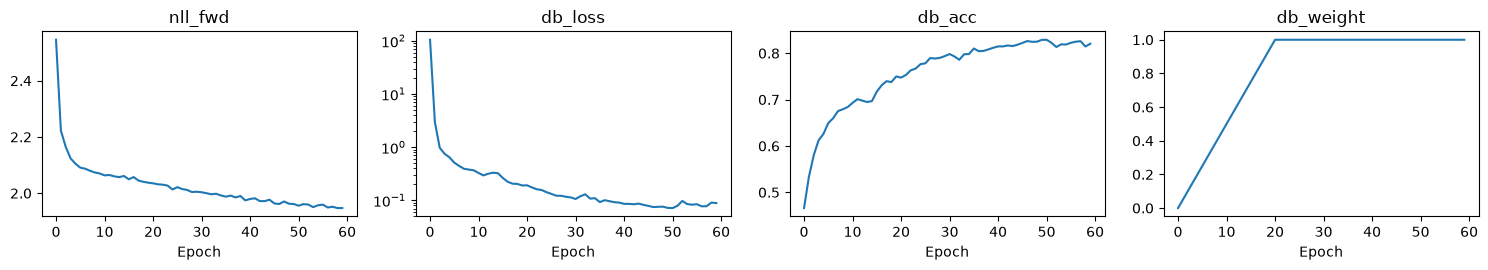

In [7]:
flow_db, hist_db = train(md_data, use_db=True)
print({k: round(v[-1], 3) for k, v in hist_db.history.items() if k in ("loss", "nll_fwd", "db_loss", "db_acc", "db_weight")})

fig, axes = plt.subplots(1, 4, figsize=(15, 2.8))
for ax, key in zip(axes, ["nll_fwd", "db_loss", "db_acc", "db_weight"]):
    ax.plot(hist_db.history[key])
    ax.set(title=key, xlabel="Epoch")
axes[1].set_yscale("log")
fig.tight_layout()
plt.show()

## 6. Comparison with the exact kernel

In [8]:
models = {"NLL only": flow_nll, "NLL + DB": flow_db}
scores = {name: evaluate(m) for name, m in models.items()}

print(f"{'model':10s} | {'KL_md':>9s} | {'KL_broad':>9s} | {'DB_rms':>9s}")
for name, s in scores.items():
    print(f"{name:10s} | {s['KL_md']:9.3f} | {s['KL_broad']:9.3f} | {s['DB_rms']:9.3f}")

model      |     KL_md |  KL_broad |    DB_rms
NLL only   |     4.125 |     6.362 |    43.866
NLL + DB   |     0.088 |     0.126 |     0.514


**Observation:** With only 300 MD pairs the NLL-only flow overfits clearly (KL ≈ 4–6, DB residual on arbitrary pairs ≈ 40), whereas the flow with DB loss reaches KL ≈ 0.1 and a DB residual of about 0.5. The baseline is deliberately unregularized (no early stopping, no weight decay): the point is that the DB term supplies information that the few samples cannot. These values are not the limit of the method: neither the architecture nor the training (epochs, learning rate, DB-weight schedule, number of DB points) was tuned, so the accuracy of the DB-regularized flow can very likely be increased further.

### Detailed balance, left side vs. right side

In log form, the DB equation for a pair `(v_i, v_r)` reads

`log q(v_r | v_i) + log J_fwd + log M_i   =   log q(−v_i | −v_r) + log J_bwd + log M_r`

(`log J` are the Jacobian terms of the abstract variables, `log M` includes the flux factor `|n|`.)
Each point below is one pair, with the **left side on the x-axis** and the **right side on the y-axis**.
If detailed balance holds, all points lie on the diagonal. Two sets of pairs are shown: arbitrary pairs (the points the DB loss is trained on)
and pairs drawn from the true kernel (where the probability mass is). In the first figure, points outside the plotted window are not drawn but counted;
the second figure shows the same arbitrary pairs on a symmetric-log scale without cutting anything off.

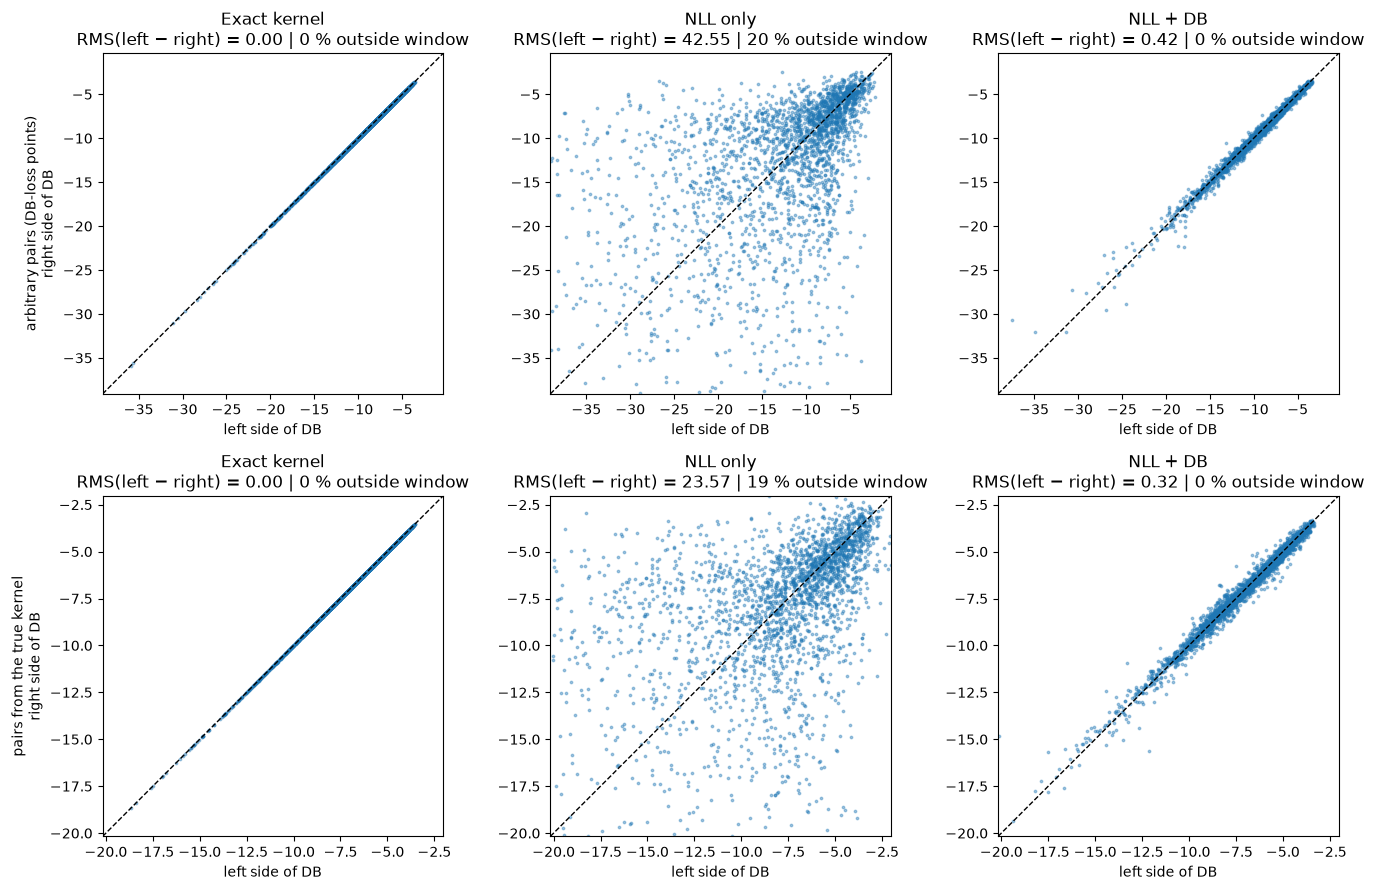

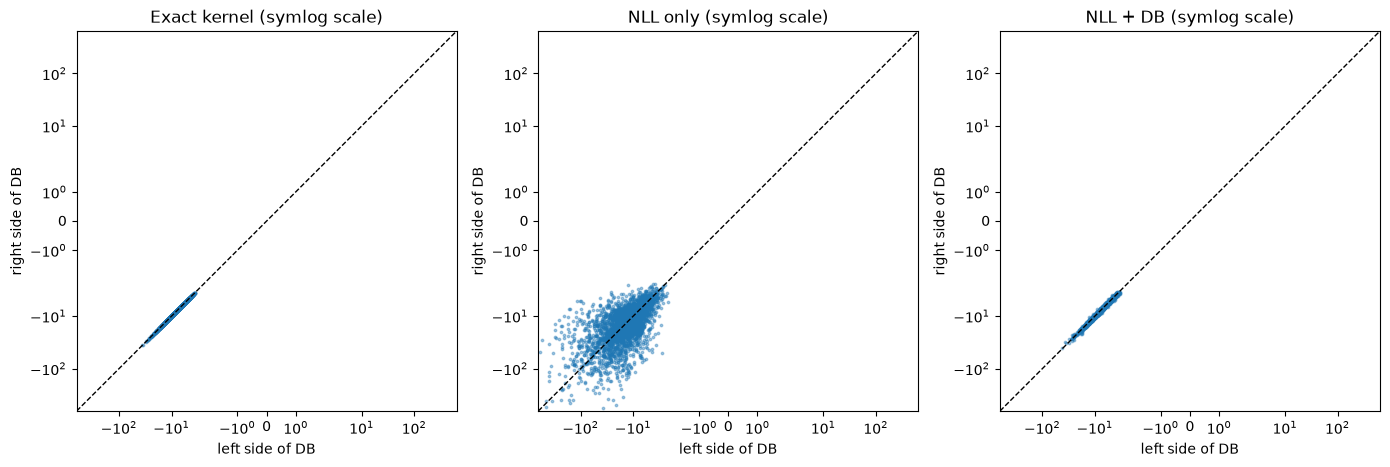

In [9]:
def db_sides(model, pairs):
    """Left and right side of the DB equation (log form) of a model for physical pairs (t_i, u_i, t_r, u_r)."""
    a = pair_arrays(*pairs)
    lhs = model.log_prob(a["v_r"], a["v_i"]).numpy() + a["log_det_jacobian_fwd"] + a["log_M_i"]
    rhs = model.log_prob(a["v_r_bwd"], a["v_i_bwd"]).numpy() + a["log_det_jacobian_bwd"] + a["log_M_r"]
    return lhs, rhs


def db_sides_exact(pairs):
    t_i, u_i, t_r, u_r = pairs
    return (log_kernel_phys(t_r, u_r, t_i, u_i) + log_M(t_i, u_i),
            log_kernel_phys(-t_i, u_i, -t_r, u_r) + log_M(t_r, u_r))


g = np.random.default_rng(123)       # separate generator: leaves the random stream of the other cells untouched
n_plot = 3000
t_i, t_r = g.normal(0, 1.5, n_plot), g.normal(0, 1.5, n_plot)
u_i, u_r = g.uniform(0.1, 3.5, n_plot), g.uniform(0.1, 3.5, n_plot)
pair_sets = {"arbitrary pairs (DB-loss points)": (t_i, u_i, t_r, u_r),
             "pairs from the true kernel": (t_i, u_i, *reflect(t_i, u_i, g))}

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for row, (set_name, pairs) in enumerate(pair_sets.items()):
    sides = {"Exact kernel": db_sides_exact(pairs)}
    sides.update({name: db_sides(m, pairs) for name, m in models.items()})

    exact = np.concatenate(sides["Exact kernel"])                  # plotting window from the exact values
    lo, hi = exact.min(), exact.max()
    lo, hi = lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo)

    for ax, (name, (lhs, rhs)) in zip(axes[row], sides.items()):
        inside = (lhs > lo) & (lhs < hi) & (rhs > lo) & (rhs < hi)
        finite = np.isfinite(lhs) & np.isfinite(rhs)
        rms = np.sqrt(np.mean((lhs[finite] - rhs[finite]) ** 2))
        ax.scatter(lhs[inside], rhs[inside], s=3, alpha=0.4)
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set(xlim=(lo, hi), ylim=(lo, hi), aspect="equal", xlabel="left side of DB",
               title=f"{name}\nRMS(left − right) = {rms:.2f} | {100 * (1 - inside.mean()):.0f} % outside window")
    axes[row, 0].set_ylabel(f"{set_name}\nright side of DB")
fig.tight_layout()
plt.show()

# the same arbitrary pairs on a symmetric-log scale: no point is cut off, the failure of the NLL-only flow becomes visible
pairs = pair_sets["arbitrary pairs (DB-loss points)"]
sides = {"Exact kernel": db_sides_exact(pairs)}
sides.update({name: db_sides(m, pairs) for name, m in models.items()})
all_vals = np.concatenate([np.concatenate(v) for v in sides.values()])
lim = 1.1 * np.abs(all_vals[np.isfinite(all_vals)]).max()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (name, (lhs, rhs)) in zip(axes, sides.items()):
    ax.scatter(lhs, rhs, s=3, alpha=0.4)
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=1)
    ax.set(xscale="symlog", yscale="symlog", xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal",
           title=f"{name} (symlog scale)", xlabel="left side of DB", ylabel="right side of DB")
fig.tight_layout()
plt.show()

**Observation:** For the exact kernel all points lie on the diagonal (RMS 0), which confirms the equation. The NLL-only flow violates detailed balance: about 20 % of its points fall outside the window of the first figure (RMS ≈ 25–45), and in the symlog plot left and right side scatter widely, only loosely following the diagonal. The DB-regularized flow scatters closely around the diagonal (RMS ≈ 0.3–0.4), widest for improbable pairs in the tails, where the model is least constrained.

### Conditional density for one incident velocity

Learned densities are converted back to physical space (`q_phys = q_abs / u_r`).

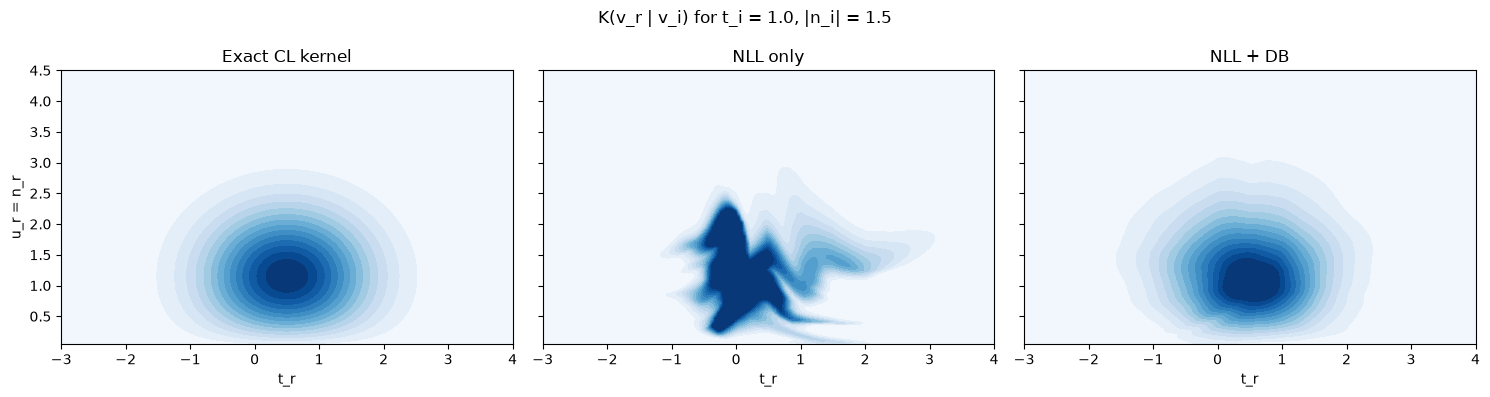

In [10]:
t_i0, u_i0 = 1.0, 1.5
tg, ug = np.meshgrid(np.linspace(-3, 4, 160), np.linspace(0.05, 4.5, 160))
y_grid = np.stack([tg.ravel(), np.log(ug.ravel())], axis=1).astype("float32")
cond_grid = np.tile([[t_i0, np.log(u_i0)]], (len(y_grid), 1)).astype("float32")

dens_exact = np.exp(log_kernel_phys(tg.ravel(), ug.ravel(), t_i0, u_i0)).reshape(tg.shape)
levels = np.linspace(0, dens_exact.max(), 16)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
panels = [("Exact CL kernel", dens_exact)]
for name, m in models.items():
    d = np.exp(m.log_prob(y_grid, cond_grid).numpy()) / ug.ravel()
    panels.append((name, np.nan_to_num(d.reshape(tg.shape))))
for ax, (title, d) in zip(axes, panels):
    ax.contourf(tg, ug, np.minimum(d, levels[-1]), levels=levels, cmap="Blues")
    ax.set(title=title, xlabel="t_r")
axes[0].set_ylabel("u_r = n_r")
fig.suptitle(f"K(v_r | v_i) for t_i = {t_i0}, |n_i| = {u_i0}")
fig.tight_layout()
plt.show()

**Observation:** The NLL-only flow memorizes the training pairs and produces thin filaments in the density. The flow with DB loss reproduces a single smooth lobe at the right position and with roughly the right width; its maximum is slightly shifted to smaller `u_r`. With a tuned model and training this offset can likely be reduced.

### Moments as a function of the incident velocity

Reflected tangential mean (exact: `(1 − α_t)·t_i`) and reflected normal median (exact: Rice distribution).

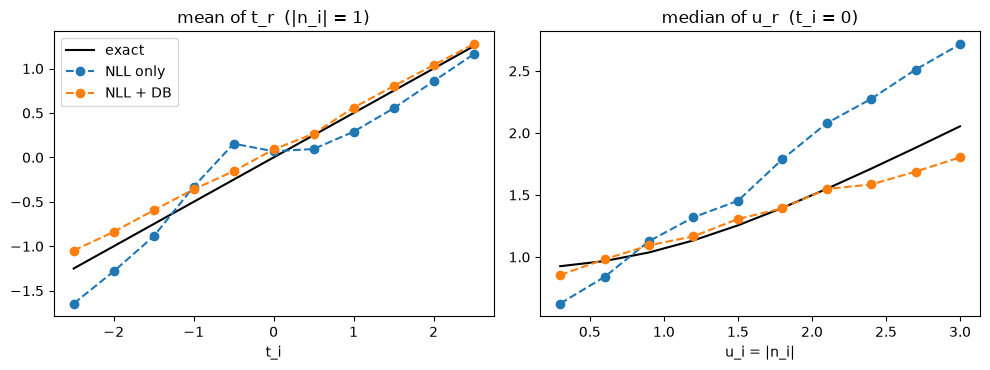

In [11]:
def reflected(model, t_i, u_i, n=2000):
    cond = np.stack([t_i, np.log(u_i)], axis=1).astype("float32")
    y = model.sample(n, cond=cond).numpy()                      # (B, n, 2) in abstract variables
    return y[..., 0], np.exp(np.clip(y[..., 1], -20, 20))        # t_r, u_r

t_axis = np.linspace(-2.5, 2.5, 11)
u_axis = np.linspace(0.3, 3.0, 10)
s_ = np.sqrt(ALPHA_N)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(t_axis, RHO * t_axis, "k", label="exact")
axes[1].plot(u_axis, stats.rice.median(np.sqrt(1 - ALPHA_N) * u_axis / s_, scale=s_), "k", label="exact")
for name, m in models.items():
    t_r, _ = reflected(m, t_axis, np.full_like(t_axis, 1.0))
    _, u_r = reflected(m, np.zeros_like(u_axis), u_axis)
    axes[0].plot(t_axis, t_r.mean(axis=1), "o--", label=name)
    axes[1].plot(u_axis, np.median(u_r, axis=1), "o--", label=name)
axes[0].set(title="mean of t_r  (|n_i| = 1)", xlabel="t_i")
axes[1].set(title="median of u_r  (t_i = 0)", xlabel="u_i = |n_i|")
axes[0].legend()
fig.tight_layout()
plt.show()

**Observation:** The DB-regularized flow follows the exact mean of `t_r` closely (slightly attenuated for `t_i < −1`) and the exact median of `u_r` up to `u_i ≈ 2`; beyond that it is somewhat too low (about 12 % at `u_i = 3`). The NLL-only flow deviates more, especially for large normal velocities, which are rare in the equilibrium training data: at `u_i = 3` its median of `u_r` is too large by about a third. The deviation at large `u_i` is not a limit of the method: more DB points in this region, longer training or a tuned DB weight should improve it further.

## 7. Physical check: equilibrium is preserved

If particles arrive with the equilibrium flux distribution (`t ~ N(0,1)`, `|n| ~ Rayleigh(1)`), a kernel in detailed balance
returns the **same** distribution. This is checked here for the learned kernels, one reflected sample per incident particle.
(The exact kernel gives KS ≈ 0.002 for the same test.)

In [12]:
n = 20_000
t_eq, u_eq = rng.standard_normal(n), rng.rayleigh(1.0, n)
cond_eq = np.stack([t_eq, np.log(u_eq)], axis=1).astype("float32")

print(f"{'model':10s} | {'finite':>7s} | {'KS(t, N(0,1))':>14s} | {'KS(u, Rayleigh)':>16s}")
for name, m in models.items():
    y = m.sample(1, cond=cond_eq).numpy()[:, 0, :]
    t_r, u_r = y[:, 0], np.exp(np.clip(y[:, 1], -20, 20))
    ok = np.isfinite(t_r) & np.isfinite(u_r)
    print(f"{name:10s} | {ok.mean():7.2f} | {stats.kstest(t_r[ok], stats.norm.cdf).statistic:14.3f} | "
          f"{stats.kstest(u_r[ok], stats.rayleigh().cdf).statistic:16.3f}")

model      |  finite |  KS(t, N(0,1)) |  KS(u, Rayleigh)
NLL only   |    1.00 |          0.042 |            0.037
NLL + DB   |    1.00 |          0.006 |            0.021


**Observation:** Both models roughly preserve equilibrium, because the MD pairs themselves come from equilibrium incidence. The DB model is closer to the exact equilibrium (KS distances 2–7 times smaller). The advantage would be larger for non-equilibrium incidence, where the NLL-only model has no training data at all.

## 8. How much data does the DB loss save?

The DB term acts as a physics-based regularizer: it is most valuable when MD data is scarce. The sweep trains both variants
for different numbers of MD pairs (same number of optimizer steps, same DB points).

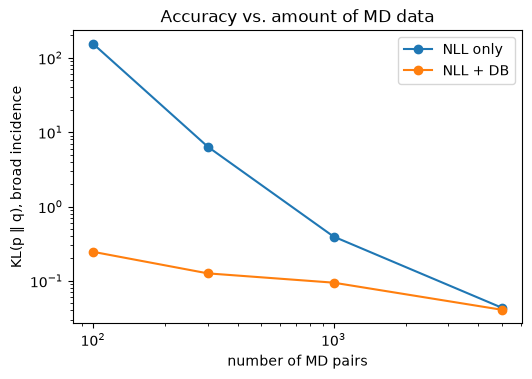

MD pairs |  KL_broad NLL only |  KL_broad NLL + DB
     100 |            154.454 |              0.246
     300 |              6.362 |              0.126
    1000 |              0.394 |              0.095
    5000 |              0.044 |              0.041


In [13]:
sweep = {N_MD: {name: scores[name] for name in models}}
for n_md in [100, 1000, 5000]:
    data = pair_arrays(*md_pairs(n_md))
    sweep[n_md] = {}
    for name, use_db in [("NLL only", False), ("NLL + DB", True)]:
        m, _ = train(data, use_db)
        sweep[n_md][name] = evaluate(m)

sizes = sorted(sweep)
fig, ax = plt.subplots(figsize=(5.8, 3.8))
for name in ["NLL only", "NLL + DB"]:
    ax.plot(sizes, [sweep[n][name]["KL_broad"] for n in sizes], "o-", label=name)
ax.set(xscale="log", yscale="log", xlabel="number of MD pairs", ylabel="KL(p ‖ q), broad incidence",
       title="Accuracy vs. amount of MD data")
ax.legend()
plt.show()

print(f"{'MD pairs':>8s} | {'KL_broad NLL only':>18s} | {'KL_broad NLL + DB':>18s}")
for n_md in sizes:
    print(f"{n_md:8d} | {sweep[n_md]['NLL only']['KL_broad']:18.3f} | {sweep[n_md]['NLL + DB']['KL_broad']:18.3f}")

**Observation:** The advantage of the DB loss is largest for scarce data (three orders of magnitude at 100 pairs) and shrinks as more MD pairs become available; at 5000 pairs both flows are about equally good. Since DB points are arbitrary pairs, they can be generated in any amount. Note that this is a single run per setting; individual numbers vary between seeds, the trend does not. The absolute KL values of both variants could be lowered further by tuning; the sweep is meant to show the relative effect of the DB loss, not the best achievable accuracy.